# Gauges and events

GHCNh station inventory, hourly series (METAR rule), QC, 5-yr/30-day validity, extreme events at 20/30/40/50 mm/h.

Cells are the original session code in execution order (exported verbatim; only secrets handling and artifact paths were changed). Each cell starts with a comment giving its original index, conda environment and run status. Exploratory and failed cells are kept, so later cells that rely on their partial state still make sense.


In [ ]:
# Setup: run from the repository root; helper modules live in prod/
import os, sys
if os.path.basename(os.getcwd())=='notebooks': os.chdir('..')
sys.path.insert(0, 'prod')
os.makedirs('out', exist_ok=True)
from style import apply_figure_style  # stand-in for the figure style used in the session


In [1]:
%%bash
# [orig cell 0 | env: python | status: ok]
for u in https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/doc/ghcnh-station-list.txt https://gpm1.gesdisc.eosdis.nasa.gov/ https://cds.climate.copernicus.eu/ https://noaa-mrms-pds.s3.amazonaws.com/ https://data.eol.ucar.edu/ https://www.ncei.noaa.gov/data/cmorph-high-resolution-global-precipitation-estimates/access/ ; do echo "$u -> $(curl -s -o /dev/null -w '%{http_code}' --max-time 20 $u)"; done

https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/doc/ghcnh-station-list.txt -> 000
https://gpm1.gesdisc.eosdis.nasa.gov/ -> 000
https://cds.climate.copernicus.eu/ -> 000
https://noaa-mrms-pds.s3.amazonaws.com/ -> 000
https://data.eol.ucar.edu/ -> 000
https://www.ncei.noaa.gov/data/cmorph-high-resolution-global-precipitation-estimates/access/ -> 000


In [2]:
%%bash
# [orig cell 1 | env: python | status: ok]
mkdir -p ghcnh && cd ghcnh
curl -s -o ghcnh-station-list.txt https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/doc/ghcnh-station-list.txt; wc -l ghcnh-station-list.txt; head -3 ghcnh-station-list.txt
grep -E " FL " ghcnh-station-list.txt | head -5; grep -cE "^US.{9} .* FL " ghcnh-station-list.txt
curl -s https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/access/by-year/ | grep -o 'href="[^"]*"' | head -20
curl -s https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/access/by-station/ | grep -o 'href="[^"]*"' | head -5

   38869 ghcnh-station-list.txt
ACL000BARA9  17.5910  -61.8210    5.0 TX BARBUDA                                      AG
ACM00078861  17.1167  -61.7833   10.0    COOLIDGE FIELD   ANTIGUA (AUX.         78861 AG
ACU55-00189  18.6000  -63.4700   10.0    SOMBRERO                                     AG
AQL000NSTP6 -14.2800 -170.7000    3.0 FL PAGO PAGO                                    AS
BDL000BEPB6  32.3667  -64.7000    2.0 FL BERMUDA ESSO PIER                            BM
CJL000LCIY2  19.6990  -80.0610    5.9 FL LITTLE CAYMAN                                KY
MXL000VERV4  19.2020  -96.1130    0.0 FL VERACURZ HARBOR                              MX
RQL000AROP4  18.4833  -66.7000    3.0 FL ARECIBO                                      PR
266


In [3]:
# [orig cell 2 | env: python | status: ok]
import pandas as pd, numpy as np, requests, re
rows=[]
for l in open('ghcnh/ghcnh-station-list.txt'):
    rows.append(dict(id=l[0:11].strip(),lat=float(l[12:20]),lon=float(l[21:30]),elev=l[31:37].strip(),st=l[38:40].strip(),name=l[41:71].strip(),rest=l[71:].strip()))
st=pd.DataFrame(rows)
fl=st[(st.st=='FL')&st.id.str.startswith('US')]
print(len(fl)); print(fl.id.str[:3].value_counts().head()); print(fl.head(8).to_string())
for u in ['https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/access/by-station/','https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/access/by-year/2020/psv/']:
    r=requests.get(u,timeout=60); print(u,r.status_code,len(r.text)); print(re.findall(r'href="([^"]+)"',r.text)[:8])

256
id
USW    111
USL     86
USC     32
USI     16
USA      9
Name: count, dtype: int64
                id     lat     lon  elev  st                name rest
27597  USA00722064  28.350 -82.617  12.0  FL  PORT RICHEY (ASOS)   US
27600  USA00722227  30.467 -87.333  26.0  FL     SAUFLEY FLD NAS   US
27649  USA00749012  30.667 -86.367  73.0  FL  EGLIN TEST SITE C5   US
27650  USA00749013  30.583 -86.450  48.0  FL  EGLIN TEST SITE C3   US
27651  USA00749014  30.617 -86.733  42.0  FL       EGLIN SITE B6   US
27657  USA00749051  29.067 -82.367  20.0  FL            DUNELLON   US
27658  USA00749053  29.350 -82.467  22.0  FL      WILLISTON MUNI   US
27659  USA00749054  28.683 -82.083  27.0  FL      BUSHNELL FIELD   US
https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/access/by-station/ 404 262
[]
https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/access/by-year/2020/psv/ 404 262
[]


In [4]:
# [orig cell 3 | env: python | status: ok]
sid='USW00012839'  # Miami Intl
base='https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/access/'
for u in [base+f'by-year/2020/psv/GHCNh_{sid}_2020.psv', base+f'by-year/2020/parquet/GHCNh_{sid}_2020.parquet', base+f'by-station/GHCNh_{sid}_por.psv', base+f'by-station/psv/GHCNh_{sid}_por.psv']:
    r=requests.head(u,timeout=60); print(r.status_code, r.headers.get('Content-Length'), u)

200 13154359 https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/access/by-year/2020/psv/GHCNh_USW00012839_2020.psv
200 1237401 https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/access/by-year/2020/parquet/GHCNh_USW00012839_2020.parquet
200 845367133 https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/access/by-station/GHCNh_USW00012839_por.psv
404 262 https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/access/by-station/psv/GHCNh_USW00012839_por.psv


> Original cell 4 ended with status **error** in the session; it is kept for the record.

In [5]:
# [orig cell 4 | env: python | status: error]
import io
r=requests.get(base+f'by-year/2020/parquet/GHCNh_{sid}_2020.parquet',timeout=120)
d=pd.read_parquet(io.BytesIO(r.content))
print(d.shape); cols=[c for c in d.columns if c.startswith('precip') or c in('DATE','Year','Month','Day','Hour','Minute')]
print(cols)
print(d[cols[:12]].dropna(subset=['precipitation']).head(15).to_string())
print(d['precipitation_Report_Type'].value_counts().head() if 'precipitation_Report_Type' in d else '')
print(d[[c for c in d.columns if 'Report_Type' in c][:1]].iloc[:,0].value_counts().head(8))

Traceback (most recent call last):
  File "<kernel:4>", line 3, in <module>
    d=pd.read_parquet(io.BytesIO(r.content))
      ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "~/.claude-science/conda/envs/python/lib/python3.11/site-packages/pandas/io/parquet.py", line 653, in read_parquet
    impl = get_engine(engine)
           ^^^^^^^^^^^^^^^^^^
  File "~/.claude-science/conda/envs/python/lib/python3.11/site-packages/pandas/io/parquet.py", line 68, in get_engine
    raise ImportError(
ImportError: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.


In [6]:
%%bash
# [orig cell 5 | env: python | status: ok]
cd ghcnh && mkdir -p pq && python - <<'EOF'
import requests, os, concurrent.futures as cf
ids=[]
for l in open('ghcnh-station-list.txt'):
    if l[38:40].strip()=='FL' and l[:2]=='US': ids.append(l[0:11].strip())
base='https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/access/by-year/'
jobs=[(s,y) for s in ids for y in range(2015,2026)]
def get(j):
    s,y=j; fn=f'pq/GHCNh_{s}_{y}.parquet'
    if os.path.exists(fn): return 'skip'
    for a in range(3):
        try:
            r=requests.get(base+f'{y}/parquet/GHCNh_{s}_{y}.parquet',timeout=120)
            if r.status_code==404: return '404'
            if r.ok: open(fn,'wb').write(r.content); return 'ok'
        except Exception as e: pass
    return 'fail'
with cf.ThreadPoolExecutor(16) as ex: res=list(ex.map(get,jobs))
from collections import Counter; print(Counter(res))
EOF
du -sh pq

Counter({'ok': 2168, '404': 648})
1.2G	pq


In [7]:
# [orig cell 6 | env: precip | status: ok]
import pandas as pd, numpy as np, glob, os
fs=sorted(glob.glob('ghcnh/pq/*.parquet')); print(len(fs))
fn='ghcnh/pq/GHCNh_USW00012839_2020.parquet'
d=pd.read_parquet(fn); print(d.shape)
pc=[c for c in d.columns if c.startswith('precipitation')]; print(pc)
print([c for c in d.columns][:20])
x=d[d.precipitation.notna()]
print(x[['DATE']+pc[:6]].head(12).to_string())

2168
(13491, 329)
['precipitation', 'precipitation_Measurement_Code', 'precipitation_Quality_Code', 'precipitation_Report_Type', 'precipitation_Source_Code', 'precipitation_Source_Station_ID', 'precipitation_5_minute', 'precipitation_5_minute_Measurement_Code', 'precipitation_5_minute_Quality_Code', 'precipitation_5_minute_Report_Type', 'precipitation_5_minute_Source_Code', 'precipitation_5_minute_Source_Station_ID', 'precipitation_15_minute', 'precipitation_15_minute_Measurement_Code', 'precipitation_15_minute_Quality_Code', 'precipitation_15_minute_Report_Type', 'precipitation_15_minute_Source_Code', 'precipitation_15_minute_Source_Station_ID', 'precipitation_3_hour', 'precipitation_3_hour_Measurement_Code', 'precipitation_3_hour_Quality_Code', 'precipitation_3_hour_Report_Type', 'precipitation_3_hour_Source_Code', 'precipitation_3_hour_Source_Station_ID', 'precipitation_6_hour', 'precipitation_6_hour_Measurement_Code', 'precipitation_6_hour_Quality_Code', 'precipitation_6_hour_Repor

In [8]:
# [orig cell 7 | env: precip | status: ok]
x=d[d.precipitation.notna()]
print(pd.crosstab(x.precipitation_Report_Type, x.Minute==53))
print(x.precipitation_Quality_Code.value_counts())
print(x.precipitation_Measurement_Code.value_counts(dropna=False).head())
# top hourly values at :53 FM-15
y=x[x.precipitation_Report_Type.str.strip()=='FM15'].sort_values('precipitation',ascending=False)
print(y[['DATE','precipitation','precipitation_Quality_Code']].head(8).to_string())
z=x[x.precipitation_Report_Type.str.strip()!='FM15']; print(z[['DATE','precipitation','precipitation_Report_Type']].head(6).to_string())

Minute                     False
precipitation_Report_Type       
FM15                        8781
FM16                         927
precipitation_Quality_Code
5    8779
1     927
P       2
Name: count, dtype: int64
precipitation_Measurement_Code
NaN    8789
T       919
Name: count, dtype: int64
                      DATE  precipitation precipitation_Quality_Code
5270   2020-05-26T22:53:00           84.6                          5
5266   2020-05-26T21:53:00           78.5                          5
10149  2020-10-02T18:53:00           40.1                          5
5108   2020-05-24T12:53:00           34.0                          5
9927   2020-09-26T23:53:00           30.5                          5
3523   2020-04-11T23:53:00           29.2                          5
4874   2020-05-19T00:53:00           29.2                          5
9834   2020-09-25T00:53:00           29.0                          5
                    DATE  precipitation precipitation_Report_Type
132  2020-01-04T2

In [9]:
%%bash
# [orig cell 8 | env: precip | status: ok]
cd ghcnh; curl -s https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/doc/ | grep -o 'href="[^"]*"' | head; for f in ghcnh_DOCUMENTATION.pdf GHCNh_DOCUMENTATION.pdf; do curl -s -o doc.pdf -w "%{http_code} $f\n" https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/doc/$f; done; file doc.pdf

200 ghcnh_DOCUMENTATION.pdf
404 GHCNh_DOCUMENTATION.pdf
doc.pdf: XML 1.0 document text, ASCII text, with no line terminators


> Original cell 9 ended with status **error** in the session; it is kept for the record.

In [10]:
%%bash
# [orig cell 9 | env: precip | status: error]
cd ghcnh; curl -s -o doc.pdf -w "%{http_code}\n" https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/doc/ghcnh_DOCUMENTATION.pdf; file doc.pdf; pip list 2>/dev/null | grep -i pdf; python -c "
import subprocess" ; which pdftotext

200
doc.pdf: PDF document, version 1.4, 8 pages


In [11]:
%%bash
# [orig cell 10 | env: precip | status: ok]
pip install -q pypdf 2>&1 | tail -1; cd ghcnh; python -c "
from pypdf import PdfReader
t='\n'.join(p.extract_text() for p in PdfReader('doc.pdf').pages)
open('doc.txt','w').write(t)
import re
i=t.find('Table 3'); print(t[i:i+2500]); j=t.find('IX.'); j=t.find('Hourly', t.find('IX')) ; print('======'); k=[m.start() for m in re.finditer('IX\\.',t)]; print(k); print(t[k[-1]:k[-1]+3000] if k else '')
"


[2466, 37817]
IX.
  
“Hourly”
 
Precipitation
 
Measurements
 
 
For
 
the
 
precipitation
 
totals
 
coming
 
from
 
METARs
 
(Meteorological
 
Aerodrome
 
Reports)
 
from
 
AWOS/ASOS
 
reports,
 
there
 
are
 
usually
 
routine
 
FM-15
 
messages
 
that
 
are
 
transmitted
 
at
 
a
 
standard
 
time
 
(near
 
the
 
end
 
of
 
the
 
hour:
 
at
 
or
 
after
 
minute
 
45)
 
for
 
a
 
particular
 
station.
 
In
 
many
 
cases,
 
the
 
report
 
is
 
hourly
 
and
 
in
 
general
 
is
 
no
 
longer
 
than
 
hourly.
 
For
 
the
 
standard
 
hourly
 
reports,
 
there
 
can
 
be
 
METAR
 
SPECI
 
(FM-16)
 
reports
 
transmitted
 
at
 
other
 
(non-standard)
 
times,
 
when
 
conditions
 
change
 
that
 
can
 
affect
 
aviation
 
during
 
the
 
hour
 
between
 
the
 
routine
 
messages.
 
Some
 
airport
 
sites
 
routinely
 
report
 
more
 
frequently
 
than
 
once
 
per
 
hour
 
(e.g,
 
at
 
20
 
minute
 
intervals),
 
even
 
when
 
conditions
 
are
 
not
 
changing.
  
When
 
multiple
 
obse

In [12]:
%%bash
# [orig cell 11 | env: precip | status: ok]
cd ghcnh; python -c "
import re
t=open('doc.txt').read(); t=re.sub(r'\s*\n\s*',' ',t)
for kw in ['Quality_Code','Quality Code','QC flag']:
  for m in list(re.finditer(kw,t))[:6]: print('>>',t[m.start()-100:m.start()+600]); print()
" | head -60

>> s: variable (see section IV, Table 1) variable _Measurement_Code (see section V, Table 2) variable _Quality_Code (see section VI, Table 3) variable _Report_Type (see section VII, Table 4) variable _Source_Code (see section XI, Table 6) variable _Source_Station_ID (original identifier provided in the data source) Where variable refers to the list of variables in Table 1 and their units. A list of potential Measurement_Codes by variable type is provided in Table 2. The list of Quality_Codes is provided in Table 3. Table 4 provides the list of possible report types. A comprehensive list of column names are provided in Section X “Columns and Headers in PSV Files” below. (B) Parquet Format Data F

>> r units. A list of potential Measurement_Codes by variable type is provided in Table 2. The list of Quality_Codes is provided in Table 3. Table 4 provides the list of possible report types. A comprehensive list of column names are provided in Section X “Columns and Headers in PSV Files” belo

In [13]:
%%bash
# [orig cell 12 | env: precip | status: ok]
cd ghcnh; python -c "
import re
t=open('doc.txt').read(); t=re.sub(r'\s*\n\s*',' ',t)
i=t.find('VI. ',t.find('Table 2')); i=t.find('Table 3',t.find('V. ')+10)
i=[m.start() for m in re.finditer('Table 3',t)][2]
print(t[i:i+3800])
"; echo; ls pq | wc -l

Table 3. Table 4 provides the list of possible report types. A comprehensive list of column names are provided in Section X “Columns and Headers in PSV Files” below. (B) Parquet Format Data Files Parquet is an open-source file format with easily-indexed columns designed for efficient data storage and retrieval. These files can be read using several languages including Python: https://arrow.apache.org/docs/python/parquet.html IV. List of Elements/Variables Table 1: Elements/Variables temperature = 2 meter (circa) Above Ground Level Air (dry bulb) Temperature ( ⁰ C to tenths) dew_point_temperature = Dew Point Temperature ( ⁰ C to tenths) station_level_pressure = the pressure that is observed at a specific elevation and is the true barometric pressure of a location. It is the pressure exerted by the atmosphere at a point as a result of gravity acting upon the "column" of air that lies directly above the point. (hPa) sea_level_pressure = reduction estimates the pressure that would exist at

In [14]:
%%bash
# [orig cell 13 | env: precip | status: ok]
cd ghcnh; python -c "
import re
t=open('doc.txt').read(); t=re.sub(r'\s*\n\s*',' ',t)
i=t.find('VI. ',t.find('Table 2:')); print(t[i:i+3500])
"

VI. List of Quality Check Codes Table 3: QC (code varies by source) VII. Report Type Codes Table 4: Report type codes VIII. Present Weather Code Descriptors Table 5: Present Weather Codes IX. “Hourly” Precipitation Measurements X. Columns and Headers in PSV Files XI. Data Source Codes and Attributes Table 6: Data Source Codes I. DOWNLOAD QUICK START Bulk GHCNh station data download access is available in three ways: 1. Period of record station files (data for all years for a single station) 2. Station/year files (one year of data for a single station) 3. A tar file of all station files for a particular year Data  Access  Locations  ●  HTTPS  WAF: 1.  https://www.ncei.noaa.gov/oa/global-historical-climatology-network/index.html#hourly/access/by-station/GHCNh_<station>_por.psv 2. https://www.ncei.noaa.gov/oa/global-historical-climatology-network/index.html#hourly/access/by-year/<YYYY>/GHCNh_<station>_<YYYY>.psv 3. https://www.ncei.noaa.gov/oa/global-historical-climatology-network/index.h

In [16]:
# [orig cell 15 | env: precip | status: ok]
from collections import Counter
import concurrent.futures as cf
cols=['STATION','DATE','Minute','precipitation','precipitation_Quality_Code','precipitation_Report_Type','precipitation_Source_Code','precipitation_Measurement_Code']
def rd(f):
    try:
        x=pd.read_parquet(f,columns=cols)
    except Exception as e:
        return None
    return x[x.precipitation.notna()]
with cf.ThreadPoolExecutor(8) as ex: parts=list(ex.map(rd,fs:=sorted(glob.glob('ghcnh/pq/*.parquet'))))
bad=[f for f,p in zip(fs,parts) if p is None]; print('unreadable',len(bad))
P=pd.concat([p for p in parts if p is not None],ignore_index=True); print(P.shape)
for c in cols[4:]: print(c, P[c].astype(str).str.strip().value_counts().head(15).to_dict())
P.to_parquet('ghcnh/fl_precip_raw.parquet')

unreadable 0
(7578769, 8)
precipitation_Quality_Code {'5': 4451779, '1': 775948, 'P': 2260, 'I': 98, 'G': 6, '2': 5}
precipitation_Report_Type {'FM15': 4616242, 'H-derived-HPD-C-high-res': 2066369, 'FM16': 354910, 'SHEF': 258938}
precipitation_Source_Code {'343': 4454137, '382': 2066369, '223': 517015, '345': 282310, '222': 258938}
precipitation_Measurement_Code {'T': 369933}


In [17]:
# [orig cell 16 | env: precip | status: ok]
P['src']=P.precipitation_Source_Code.astype(str).str.strip(); P['rt']=P.precipitation_Report_Type.astype(str).str.strip()
P['qc']=P.precipitation_Quality_Code.astype(str).str.strip()
print(pd.crosstab(P.src,P.rt)); print(pd.crosstab(P.src,P.qc))
P['Minute']=pd.to_numeric(P.Minute)
for s in P.src.unique(): print(s, P[P.src==s].Minute.value_counts().head(6).to_dict(), P[P.src==s].STATION.nunique(), P[P.src==s].STATION.str[:3].value_counts().to_dict())

rt      FM15    FM16  H-derived-HPD-C-high-res    SHEF
src                                                   
222        0       0                         0  258938
223   162105  354910                         0       0
343  4454137       0                         0       0
382        0       0                   2066369       0
qc        1  2        5  G   I     P
src                                 
222  258938  0        0  0   0     0
223  517010  5        0  0   0     0
343       0  0  4451779  0  98  2260
382       0  0        0  6   0     0
382 {0: 2066369} 32 {'USC': 2066369}
223 {55: 54287, 56: 41036, 35: 29242, 15: 22356, 58: 17750, 0: 10253} 92 {'USW': 440710, 'USI': 76305}
222 {0: 258909, 45: 29} 3 {'USL': 258938}
343 {53: 3658180, 56: 396757, 52: 91800, 58: 84119, 55: 58968, 51: 42470} 80 {'USW': 4454137}
345 {0: 282310} 3 {'USW': 282310}


In [18]:
# [orig cell 17 | env: precip | status: ok]
P['t']=pd.to_datetime(P.DATE)
P=P[~P.qc.isin(['2','G'])]
met=P[P.src.isin(['343','223'])&(P.rt=='FM15')]
# AWOS check: stations whose FM15 come at minutes <45
frac=met.groupby('STATION').Minute.apply(lambda m:(m<45).mean()); print('stations w >20% FM15 at min<45:',(frac>0.2).sum()); print(frac[frac>0.2].round(2).to_dict())
m45=met[met.Minute>=45].copy()
m45['hr']=m45.t.dt.floor('h')   # interval start = clock hour of routine report
m45=m45.sort_values('t').groupby(['STATION','hr']).precipitation.last().reset_index()
oth=P[P.src.isin(['382','222','345'])].copy()
oth['hr']=oth.t.dt.floor('h')-pd.Timedelta(hours=1)  # provisional: hour-ending stamp -> interval start
oth=oth.groupby(['STATION','hr']).precipitation.last().reset_index()
both=set(m45.STATION)&set(oth.STATION); print('stations in both groups',len(both))
H=pd.concat([m45.assign(grp='metar'),oth[~oth.STATION.isin(set(m45.STATION))].assign(grp='onhour')])
H=H.drop_duplicates(['STATION','hr']); print(H.shape, H.STATION.nunique(), H.groupby('grp').STATION.nunique().to_dict())
H.to_parquet('ghcnh/fl_hourly.parquet')

stations w >20% FM15 at min<45: 30
{'USI0000K28J': 0.41, 'USI0000K2IS': 0.58, 'USI0000K54J': 0.58, 'USI0000KF45': 0.61, 'USI0000KLCQ': 0.58, 'USI0000KMKY': 0.25, 'USI0000KSEF': 0.58, 'USI0000KX26': 0.57, 'USI0000KX60': 0.52, 'USW00000235': 0.58, 'USW00000299': 0.57, 'USW00000325': 0.58, 'USW00000326': 0.58, 'USW00000360': 0.46, 'USW00000377': 0.57, 'USW00000415': 0.42, 'USW00000482': 0.23, 'USW00000485': 0.56, 'USW00000486': 0.57, 'USW00012809': 0.55, 'USW00012833': 0.22, 'USW00012883': 0.72, 'USW00053862': 0.51, 'USW00063823': 0.52, 'USW00063871': 0.23, 'USW00092815': 0.55, 'USW00092816': 0.56, 'USW00092824': 0.57, 'USW00092825': 0.58, 'USW00092828': 0.58}
stations in both groups 0
(7063064, 4) 132 {'metar': 94, 'onhour': 38}


In [19]:
# [orig cell 18 | env: precip | status: ok]
aw=met[met.STATION.isin(frac[frac>0.2].index)].copy()
aw['ch']=aw.t.dt.floor('h')
# for clock-hour groups with >=2 reports and some rain: is value nondecreasing in time & is minute>=45 value the max?
g=aw.sort_values('t').groupby(['STATION','ch'])
s=g.precipitation.agg(['count','max','last']); r=s[(s['count']>=2)&(s['max']>0)]
print(len(r), 'last==max frac', (r['last']==r['max']).mean().round(3))
mono=g.precipitation.apply(lambda v: bool(np.all(np.diff(v.values)>=-0.01)))
print('monotone frac (rainy)', mono.loc[r.index].mean().round(3))
ex=aw[(aw.STATION=='USW00092815')&(aw.precipitation>0)].head(12)[['t','precipitation']]; print(ex.to_string())

59161 last==max frac 0.981
monotone frac (rainy) 0.98
                          t  precipitation
6990980 2015-01-01 02:15:00            0.2
6990981 2015-01-01 02:35:00            0.2
6990982 2015-01-01 02:55:00            0.2
6990983 2015-01-01 05:15:00            1.5
6990984 2015-01-01 05:35:00            1.8
6990985 2015-01-01 05:55:00            1.8
6990986 2015-01-02 03:35:00            0.3
6990987 2015-01-02 03:55:00            0.8
6990988 2015-01-02 04:35:00            0.3
6990989 2015-01-02 04:55:00            0.3
6990990 2015-01-02 05:35:00            0.8
6990991 2015-01-02 05:55:00            2.8


In [20]:
# [orig cell 19 | env: precip | status: ok]
H['day']=H.hr.dt.floor('D')
dc=H.groupby(['STATION','day']).hr.nunique().reset_index(name='nh')
dc['complete']=dc.nh==24; dc['year']=dc.day.dt.year
yc=dc.groupby(['STATION','year']).complete.sum().unstack(fill_value=0).reindex(columns=range(2015,2026),fill_value=0)
validyr=(yc>=30); nvy=validyr.sum(1)
meta=st.set_index('id') if 'st' in dir() else None
rows=[]
for l in open('ghcnh/ghcnh-station-list.txt'):
    rows.append(dict(id=l[0:11].strip(),lat=float(l[12:20]),lon=float(l[21:30]),elev=l[31:37].strip(),state=l[38:40].strip(),name=l[41:71].strip()))
S=pd.DataFrame(rows).set_index('id')
allfl=S[(S.state=='FL')&S.index.str.startswith('US')]
inv=allfl.copy(); inv['years_with_file']=pd.Series(Counter(os.path.basename(f).split('_')[1] for f in fs)); inv['years_with_file']=inv.years_with_file.fillna(0).astype(int)
inv['has_hourly_precip']=inv.index.isin(H.STATION.unique())
inv['n_valid_years']=nvy.reindex(inv.index).fillna(0).astype(int)
inv['valid']=inv.n_valid_years>=5
inv['source_group']=H.groupby('STATION').grp.first().reindex(inv.index)
print(inv.has_hourly_precip.sum(), inv.valid.sum()); print(inv[inv.valid].source_group.value_counts().to_dict())
print(nvy.value_counts().sort_index().to_dict())
os.makedirs('out',exist_ok=True)
inv.reset_index().rename(columns={'index':'id'}).to_csv('out/fl_station_inventory.csv',index=False)
V=inv[inv.valid].copy(); V['valid_years']=[','.join(str(y) for y in validyr.columns[validyr.loc[s]]) for s in V.index]
V['complete_days_total']=yc.loc[V.index].sum(1)
V.reset_index().rename(columns={'index':'id'}).to_csv('out/valid_stations.csv',index=False)
yc.to_csv('out/complete_days_by_station_year.csv')

132 79
{'metar': 48, 'onhour': 31}
{0: 44, 1: 1, 2: 5, 3: 1, 4: 2, 6: 3, 7: 2, 8: 1, 9: 2, 10: 5, 11: 66}


<kernel:8>:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  validyr=(yc>=30); nvy=validyr.sum(1)
<kernel:8>:22: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  V['complete_days_total']=yc.loc[V.index].sum(1)

In [21]:
# [orig cell 20 | env: precip | status: ok]
rej=inv[inv.has_hourly_precip&~inv.valid]
hrs=H.groupby('STATION').hr.count(); mxd=yc.max(1); mnh=dc.groupby('STATION').nh.median()
t=rej.assign(nhours=hrs, max_cd_yr=mxd, median_hrs_per_day=mnh)[['name','source_group','nhours','max_cd_yr','median_hrs_per_day','n_valid_years']].sort_values('nhours',ascending=False)
print(t.head(25).to_string())

                                     name source_group  nhours  max_cd_yr  median_hrs_per_day  n_valid_years
id                                                                                                          
USW00003855  PENSACOLA FOREST SHERMAN NAS        metar   29631         96                11.0              4
USW00012833                 CROSS CITY AP        metar   18159        355                 6.0              2
USC00083538               GRACEVILLE 1 SW       onhour   17111        206                24.0              4
USW00012826                 HOMESTEAD AFB        metar   13391          1                 4.0              0
USW00003852       VALPARAISO HURLBURT FLD        metar   12363          1                 4.0              0
USC00087440          RAIFORD STATE PRISON       onhour   12305        332                24.0              2
USC00082391              DOWLING PARK 1 W       onhour   12232        172                24.0              3
USW00012810        

<kernel:9>:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  hrs=H.groupby('STATION').hr.count(); mxd=yc.max(1); mnh=dc.groupby('STATION').nh.median()

> Original cell 22 ended with status **error** in the session; it is kept for the record.

In [23]:
# [orig cell 22 | env: precip | status: error]
import matplotlib as mpl, matplotlib.pyplot as plt
try: apply_figure_style(); print('style ok')
except NameError: print('no style fn')
import cartopy.crs as ccrs, cartopy.feature as cfeat
fig=plt.figure(figsize=(10,5.2))
ax=fig.add_subplot(1,2,1,projection=ccrs.PlateCarree()); ax.set_extent([-87.8,-79.8,24.3,31.1])
ax.add_feature(cfeat.STATES.with_scale('10m'),lw=0.5,edgecolor='0.4'); ax.add_feature(cfeat.COASTLINE.with_scale('10m'),lw=0.5)
c={'METAR (ASOS)':'#1f77b4','Coop HPD / other hourly':'#e08214'}
nop=inv[~inv.has_hourly_precip]; ax.scatter(nop.lon,nop.lat,s=6,c='0.75',label=f'no hourly precip (n={len(nop)})',transform=ccrs.PlateCarree())
rj=inv[inv.has_hourly_precip&~inv.valid]; ax.scatter(rj.lon,rj.lat,s=18,facecolors='none',edgecolors='k',lw=0.7,label=f'fails 5-yr/30-day rule (n={len(rj)})')
for g,lab in [('metar','METAR (ASOS)'),('onhour','Coop HPD / other hourly')]:
    v=inv[inv.valid&(inv.source_group==g)]; ax.scatter(v.lon,v.lat,s=22,c=c[lab],label=f'valid – {lab} (n={len(v)})',edgecolors='k',lw=0.3)
ax.legend(loc='lower left',fontsize=6.5,frameon=False); ax.set_title('79 of 256 Florida GHCNh stations pass the validity rule',loc='left',fontsize=9)
ax2=fig.add_subplot(1,2,2)
Y=yc.loc[yc.index.isin(inv[inv.has_hourly_precip].index)].copy()
Y=Y.loc[Y.sum(axis=1).sort_values(ascending=False).index]
im=ax2.imshow(Y.values,aspect='auto',cmap='viridis',vmin=0,vmax=366,interpolation='nearest')
ax2.contour(np.arange(11),np.arange(len(Y)),(Y.values>=30).astype(float),levels=[0.5],colors='w',linewidths=0.6)
ax2.set_xticks(range(11)); ax2.set_xticklabels(range(2015,2026),rotation=90,fontsize=7); ax2.set_yticks([])
ax2.set_ylabel(f'stations with hourly precip (n={len(Y)}), sorted'); ax2.set_title('Complete (24-h) UTC days per station-year',loc='left',fontsize=9)
cb=fig.colorbar(im,ax=ax2,fraction=0.05); cb.set_label('complete days (white contour = 30)')
fig.tight_layout(); fig.savefig('out/fl_stations_validity.png',dpi=200)

style ok


Matplotlib is building the font cache; this may take a moment.
Traceback (most recent call last):
  File "~/.claude-science/conda/envs/precip/lib/python3.11/pathlib.py", line 1116, in mkdir
    os.mkdir(self, mode)
FileNotFoundError: [Errno 2] No such file or directory: '~/.local/share/cartopy/shapefiles/natural_earth/cultural'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "~/.claude-science/conda/envs/precip/lib/python3.11/pathlib.py", line 1116, in mkdir
    os.mkdir(self, mode)
FileNotFoundError: [Errno 2] No such file or directory: '~/.local/share/cartopy/shapefiles/natural_earth'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "~/.claude-science/conda/envs/precip/lib/python3.11/pathlib.py", line 1116, in mkdir
    os.mkdir(self, mode)
FileNotFoundError: [Errno 2] No such file or directory: '~/.local/share/cartopy/shapefiles'

During handling of the abov

> Original cell 23 ended with status **error** in the session; it is kept for the record.

In [24]:
# [orig cell 23 | env: precip | status: error]
import cartopy
cartopy.config['data_dir']=os.path.abspath('cartopy_data'); os.makedirs('cartopy_data',exist_ok=True)
fig.savefig('out/fl_stations_validity.png',dpi=200)
r = fig.canvas.get_renderer()
texts=[t for t in fig.findobj(mpl.text.Text) if t.get_text().strip() and t.get_visible()]
bb=[t.get_window_extent(r) for t in texts]
ov=[(texts[i].get_text(),texts[j].get_text()) for i in range(len(bb)) for j in range(i+1,len(bb)) if bb[i].overlaps(bb[j])]
print(ov[:5])

~/.claude-science/conda/envs/precip/lib/python3.11/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_1_states_provinces_lakes.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
~/.claude-science/conda/envs/precip/lib/python3.11/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
Traceback (most recent call last):
  File "<kernel:12>", line 3, in <module>
    fig.savefig('out/fl_stations_validity.png',dpi=200)
  File "~/.claude-science/conda/envs/precip/lib/python3.11/site-packages/matplotlib/figure.py", line 3515, in savefig
    self.canvas.print_figure(fname, **kwargs)
  File "~/.claude-science/conda/envs/precip/lib/python3.11/site-packages/matplotlib/backend_bases.py", line 2257, in print_figure
    self.figure.draw(renderer)
  File "~/.claude-s

saved
[]


~/.claude-science/conda/envs/precip/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
~/.claude-science/conda/envs/precip/lib/python3.11/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
~/.claude-science/conda/envs/precip/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)

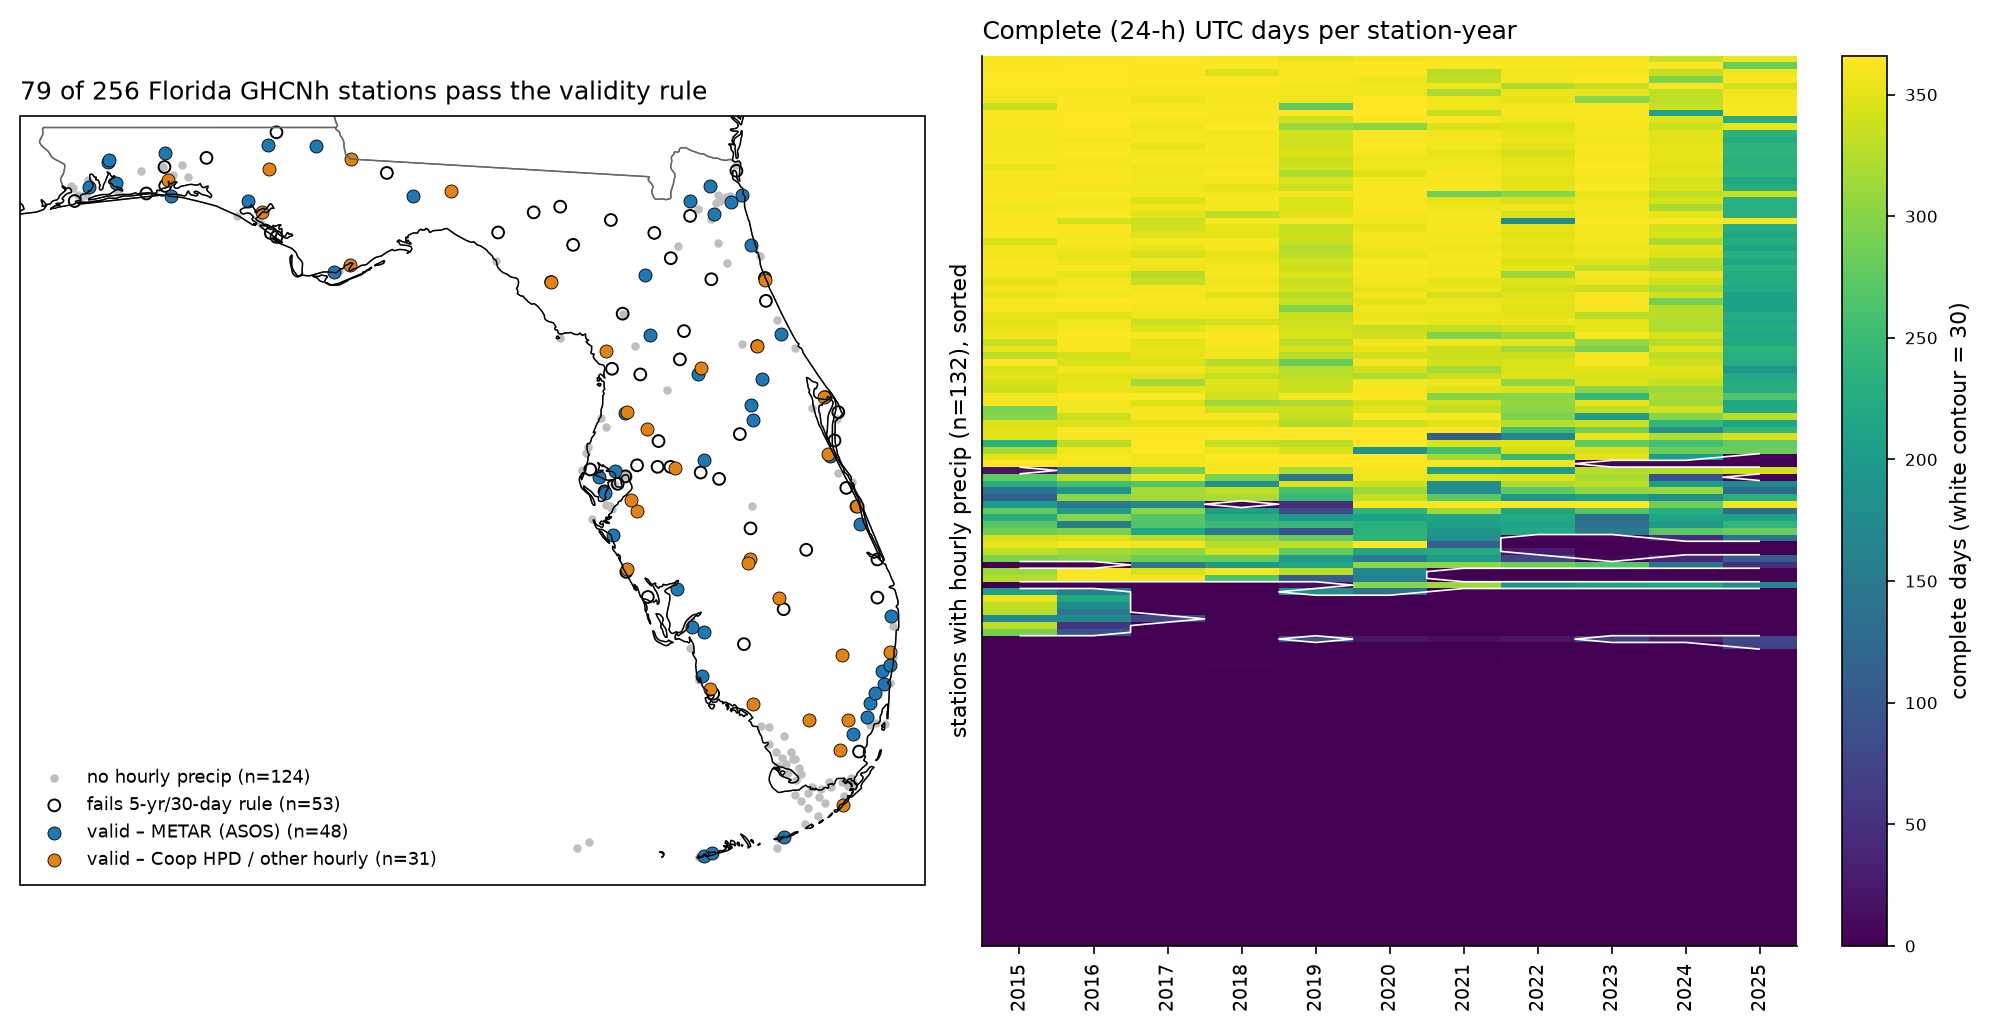

In [25]:
# [orig cell 24 | env: precip | status: ok]
import shutil
for k in range(3):
    try:
        fig.savefig('out/fl_stations_validity.png',dpi=200); print('saved'); break
    except Exception as e:
        print('retry',type(e).__name__); 
r = fig.canvas.get_renderer()
texts=[t for t in fig.findobj(mpl.text.Text) if t.get_text().strip() and t.get_visible()]
bb=[t.get_window_extent(r) for t in texts]
print([(texts[i].get_text(),texts[j].get_text()) for i in range(len(bb)) for j in range(i+1,len(bb)) if bb[i].overlaps(bb[j])][:5])

In [26]:
# [orig cell 25 | env: precip | status: ok]
Hv=H[H.STATION.isin(V.index)].copy(); Hv['year']=Hv.hr.dt.year
vy=validyr.stack(); vy=vy[vy].reset_index()[['STATION','year']]
Hv=Hv.merge(vy,on=['STATION','year'])
Hv=Hv.sort_values(['STATION','hr']).reset_index(drop=True)
# neighbour context
Hv['prev']=Hv.groupby('STATION').precipitation.shift(1).where(Hv.groupby('STATION').hr.shift(1)==Hv.hr-pd.Timedelta('1h'))
Hv['next']=Hv.groupby('STATION').precipitation.shift(-1).where(Hv.groupby('STATION').hr.shift(-1)==Hv.hr+pd.Timedelta('1h'))
Hv.to_parquet('ghcnh/fl_hourly_valid.parquet')
ext=Hv[Hv.precipitation>=20].copy()
ext['flag']=''
ext.loc[ext.precipitation>150,'flag']+='gt150;'
ext.loc[ext.prev.isna()&ext.next.isna(),'flag']+='isolated_neighbours_missing;'
ext.loc[(ext.prev==0)&(ext.next==0)&(ext.precipitation>=50),'flag']+='dry_both_sides;'
ext=ext.join(V[['name','lat','lon','source_group']],on='STATION')
print(len(ext), ext.flag.value_counts().to_dict()); print(ext.sort_values('precipitation',ascending=False).head(10)[['STATION','name','hr','precipitation','prev','next','flag']].to_string())

8632 {'': 8606, 'dry_both_sides;': 14, 'isolated_neighbours_missing;': 11, 'gt150;': 1}
             STATION                            name                  hr  precipitation  prev  next             flag
2201566  USL000RKXF1             ROOKERY BAY RESERVE 2020-01-10 13:00:00          174.0  85.3   0.0           gt150;
6056876  USW00092806  ST PETERSBURG ALBERT WHITTED A 2024-10-10 00:00:00          134.9  65.0  60.2                 
3645658  USW00012843              VERO BEACH INTL AP 2016-05-17 18:00:00          131.8  33.5  32.3                 
2137314  USL000GTXF1         GUANA TOLOMATO MATANZAS 2023-03-06 21:00:00          113.0   0.0   NaN                 
3861813  USW00012849           FT LAUDERDALE INTL AP 2019-12-23 06:00:00          112.8  33.3  27.7                 
4059237  USW00012854              ORLANDO SANFORD AP 2021-09-19 21:00:00          107.2   6.4  13.7                 
6365337  USW00092826            EVERGLADES CITY 5 NE 2021-06-01 19:00:00          107.1  49.2

In [27]:
# [orig cell 26 | env: precip | status: ok]
nyr=vy.groupby('STATION').size()
rate=(ext.groupby('STATION').size()/nyr).fillna(0).rename('n20_per_yr')
tot=Hv.groupby('STATION').precipitation.sum()/Hv.groupby('STATION').hr.count()*8766
q=pd.concat([V[['name','source_group']],rate,tot.rename('annual_mm_est'),nyr.rename('nyears'),(ext[ext.precipitation>=50].groupby('STATION').size()/nyr).rename('n50_per_yr')],axis=1).sort_values('n20_per_yr',ascending=False)
q['grp_src']=Hv.groupby('STATION').grp.first()
print(q.head(12).round(2).to_string()); print(q.tail(6).round(2).to_string())
print(q.groupby('source_group')[['n20_per_yr','annual_mm_est']].median().round(1))

                                    name source_group  n20_per_yr  annual_mm_est  nyears  n50_per_yr grp_src
USW00013899            PENSACOLA RGNL AP        metar       16.18        1862.58      11        1.18   metar
USC00086240                    NICEVILLE       onhour       16.00        1983.21      11        1.00  onhour
USW00012839                MIAMI INTL AP        metar       15.82        1836.44      11        1.27   metar
USW00092826         EVERGLADES CITY 5 NE       onhour       15.18        1390.36      11        1.36  onhour
USW00012835         FT MYERS PAGE FLD AP        metar       14.55        1560.45      11        1.55   metar
USC00084095    HOMESTEAD GEN AVIATION AP       onhour       14.36        1683.65      11        1.36  onhour
USW00012842                TAMPA INTL AP        metar       13.18        1436.43      11        0.82   metar
USC00081048            BROOKSVILLE 7 SSW       onhour       13.18        1513.80      11        0.64  onhour
USW00012894  FT MYE

In [28]:
# [orig cell 27 | env: precip | status: ok]
print(q[q.index.str.startswith(('USL','USI'))|(q.index.isin(V.index)&(q.n20_per_yr<5))].dropna(subset=['name']).round(2).to_string())
print(ext[ext.STATION.str.startswith('USL')].sort_values('precipitation',ascending=False).head(10)[['STATION','hr','precipitation','prev','next']].to_string())

                                      name source_group  n20_per_yr  annual_mm_est  nyears  n50_per_yr grp_src
USL000GTXF1        GUANA TOLOMATO MATANZAS       onhour        7.73        1257.46      11        0.45  onhour
USL000APXF1           APALACHICOLA RESERVE       onhour        7.27        1403.60      11        0.45  onhour
USL000RKXF1            ROOKERY BAY RESERVE       onhour        7.09        1133.17      11        0.55  onhour
USW00063890  JACKSONVILLE WHITEHOUSE NAVAL        metar        4.91         951.26      11        0.45   metar
USW00012861           OCALA JIM TAYLOR FLD        metar        3.33         909.57       6         NaN   metar
             STATION                  hr  precipitation  prev   next
2201566  USL000RKXF1 2020-01-10 13:00:00          174.0  85.3    0.0
2137314  USL000GTXF1 2023-03-06 21:00:00          113.0   0.0    NaN
2025211  USL000APXF1 2020-01-11 14:00:00          106.7   0.0    0.0
2201565  USL000RKXF1 2020-01-10 12:00:00           85.3   

In [29]:
# [orig cell 28 | env: precip | status: ok]
ext.loc[(ext.prev==0)&(ext.next==0)&(ext.precipitation>=40)&(ext.precipitation<50)&(ext.flag==''),'flag']='dry_both_sides;'
ext['flag']=ext.flag.str.rstrip(';')
ext['hour_start_utc']=ext.hr; ext['hour_end_utc']=ext.hr+pd.Timedelta('1h')
summ=[]
for T in [20,30,40,50]:
    e=ext[ext.precipitation>=T].sort_values(['STATION','hr']).copy()
    gap=e.groupby('STATION').hr.diff()
    e['event_id']=(gap.isna()|(gap>=pd.Timedelta('6h'))).cumsum()
    e['event_id']=f'T{T}_'+e.event_id.astype(str).str.zfill(5)
    ev=e.groupby('event_id').agg(STATION=('STATION','first'),name=('name','first'),lat=('lat','first'),lon=('lon','first'),
        source_group=('source_group','first'),first_hour_utc=('hr','min'),last_hour_utc=('hr','max'),n_exceed_hours=('hr','size'),
        peak_mm_h=('precipitation','max'),flag=('flag',lambda f:';'.join(sorted(set(x for x in f if x)))))
    ev['peak_hour_utc']=e.loc[e.groupby('event_id').precipitation.idxmax(),['event_id','hr']].set_index('event_id').hr
    out=e[['event_id','STATION','name','lat','lon','source_group','hour_start_utc','hour_end_utc','precipitation','prev','next','flag']].rename(columns={'precipitation':'precip_mm_h','prev':'prev_hour_mm','next':'next_hour_mm'})
    out.to_csv(f'out/events_ge{T}_hours.csv',index=False); ev.reset_index().to_csv(f'out/events_ge{T}.csv',index=False)
    summ.append(dict(threshold=T,hours=len(out),events=len(ev),stations=ev.STATION.nunique(),flagged_hours=(out.flag!='').sum(),
                     wet_season_frac=round(ev.peak_hour_utc.dt.month.between(5,10).mean(),2)))
summ=pd.DataFrame(summ); print(summ.to_string(index=False)); summ.to_csv('out/event_counts_summary.csv',index=False)

 threshold  hours  events  stations  flagged_hours  wet_season_frac
        20   8632    7466        79             59             0.80
        30   3271    2996        79             52             0.83
        40   1244    1169        79             51             0.85
        50    511     485        77             17             0.86


[]


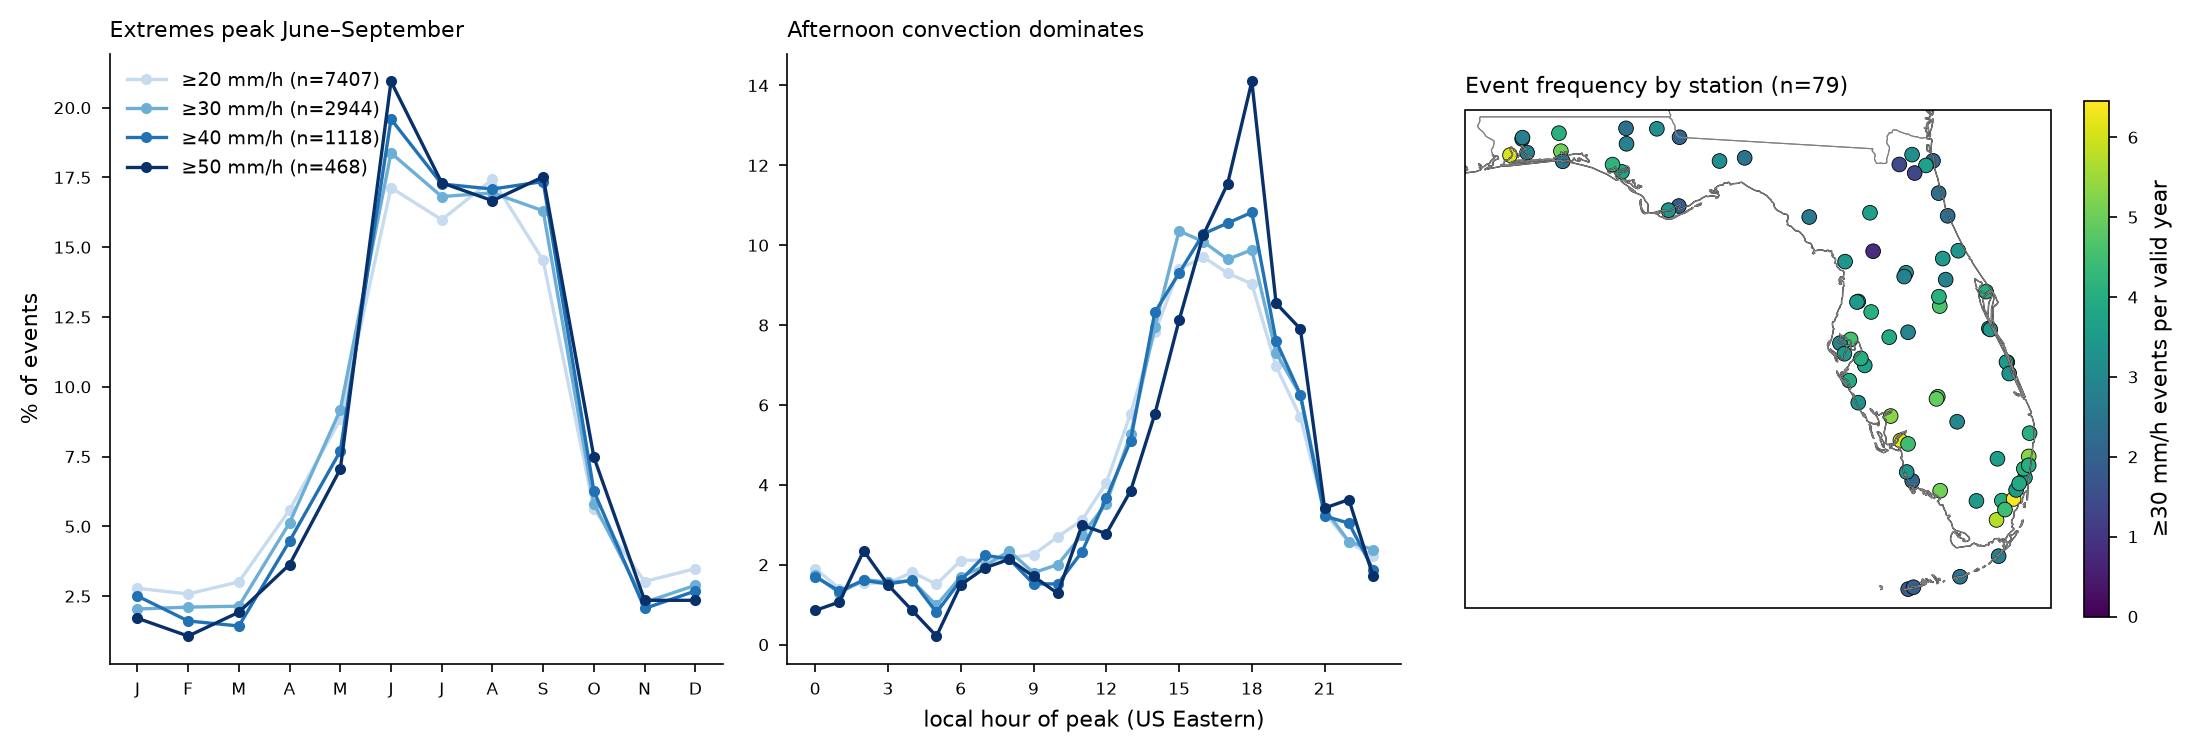

In [30]:
# [orig cell 29 | env: precip | status: ok]
E={T:pd.read_csv(f'out/events_ge{T}.csv',parse_dates=['peak_hour_utc']) for T in [20,30,40,50]}
cols={20:'#c6dbef',30:'#6baed6',40:'#2171b5',50:'#08306b'}
fig=plt.figure(figsize=(11,3.8)); gs=fig.add_gridspec(1,3,width_ratios=[1,1,1.05])
a=fig.add_subplot(gs[0]); b=fig.add_subplot(gs[1])
for T in [20,30,40,50]:
    e=E[T][E[T].flag.isna()]
    m=e.peak_hour_utc.dt.month.value_counts(normalize=True).reindex(range(1,13),fill_value=0)
    a.plot(range(1,13),m.values*100,'-o',ms=3,color=cols[T],label=f'≥{T} mm/h (n={len(e)})')
    lh=e.peak_hour_utc.dt.tz_localize('UTC').dt.tz_convert('America/New_York').dt.hour.value_counts(normalize=True).reindex(range(24),fill_value=0)
    b.plot(range(24),lh.values*100,'-o',ms=3,color=cols[T])
a.set_xticks(range(1,13)); a.set_xticklabels('JFMAMJJASOND'); a.set_ylabel('% of events'); a.set_title('Extremes peak June–September',loc='left')
a.legend(frameon=False,fontsize=7)
b.set_xticks(range(0,24,3)); b.set_xlabel('local hour of peak (US Eastern)'); b.set_title('Afternoon convection dominates',loc='left')
c=fig.add_subplot(gs[2],projection=ccrs.PlateCarree()); c.set_extent([-87.8,-79.8,24.3,31.1])
c.add_feature(cfeat.COASTLINE.with_scale('10m'),lw=0.5); c.add_feature(cfeat.STATES.with_scale('10m'),lw=0.4,edgecolor='0.5')
r30=(E[30][E[30].flag.isna()].groupby('STATION').size()/nyr).reindex(V.index).fillna(0)
sc=c.scatter(V.lon,V.lat,c=r30.values,s=28,cmap='viridis',edgecolors='k',lw=0.3,vmin=0)
cb=fig.colorbar(sc,ax=c,fraction=0.04); cb.set_label('≥30 mm/h events per valid year')
c.set_title(f'Event frequency by station (n={len(V)})',loc='left')
fig.tight_layout(); fig.savefig('out/event_climatology.png',dpi=200)
r=fig.canvas.get_renderer(); texts=[t for t in fig.findobj(mpl.text.Text) if t.get_text().strip() and t.get_visible()]
bb=[t.get_window_extent(r) for t in texts]; print([(texts[i].get_text(),texts[j].get_text()) for i in range(len(bb)) for j in range(i+1,len(bb)) if bb[i].overlaps(bb[j])][:5])

In [31]:
# [orig cell 30 | env: precip | status: ok]
e20=pd.read_csv('out/events_ge20_hours.csv',parse_dates=['hour_start_utc'])
days=e20.hour_start_utc.dt.floor('D').unique(); print('event days',len(days))
win=set()
for t in e20.hour_start_utc.unique():
    for k in range(-3,4): win.add(t+pd.Timedelta(hours=k))
print('unique window hours',len(win), 'unique window days', len({w.floor('D') for w in win}))
print('total hours 2015-2025', 11*8766)
pd.Series(sorted(win)).to_frame('hour_start_utc').to_parquet('out/needed_hours.parquet')

event days 1914
unique window hours 22744 unique window days 2112
total hours 2015-2025 96426
